In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mrdaniilak/russia-real-estate-2021")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'russia-real-estate-2021' dataset.
Path to dataset files: /kaggle/input/russia-real-estate-2021


In [2]:
import os

dataset_path = "/root/.cache/kagglehub/datasets/mrdaniilak/russia-real-estate-2021/versions/1"

print("Путь:", dataset_path)

print("Файлы:", os.listdir(dataset_path))

Путь: /root/.cache/kagglehub/datasets/mrdaniilak/russia-real-estate-2021/versions/1
Файлы: ['input_data.csv']


In [3]:
csv_file = os.path.join(path, "input_data.csv")

In [4]:
import pandas as pd
df = pd.read_csv(csv_file, sep = ';')
print("Форма (строки, столбцы):", df.shape)
print("\nСтолбцы:")
print(df.columns.tolist())

Форма (строки, столбцы): (11358150, 15)

Столбцы:
['date', 'price', 'level', 'levels', 'rooms', 'area', 'kitchen_area', 'geo_lat', 'geo_lon', 'building_type', 'object_type', 'postal_code', 'street_id', 'id_region', 'house_id']


In [5]:
pd.set_option("display.float_format", "{:.2f}".format)

In [6]:
df.head()

,date,price,level,levels,rooms,area,kitchen_area,geo_lat,geo_lon,building_type,object_type,postal_code,street_id,id_region,house_id
0,2021-01-01,2451300,15,31,1,30.30,0.00,56.78,60.70,0,2,620000.00,NaN,66,1632918.00
1,2021-01-01,1450000,5,5,1,33.00,6.00,44.61,40.14,0,0,385000.00,NaN,1,NaN
2,2021-01-01,10700000,4,13,3,85.00,12.00,55.54,37.73,3,0,142701.00,242543.00,50,681306.00
3,2021-01-01,3100000,3,5,3,82.00,9.00,44.61,40.14,0,0,385000.00,NaN,1,NaN
4,2021-01-01,2500000,2,3,1,30.00,9.00,44.74,37.71,3,2,353960.00,439378.00,23,1730985.00


In [7]:
df.tail()

,date,price,level,levels,rooms,area,kitchen_area,geo_lat,geo_lon,building_type,object_type,postal_code,street_id,id_region,house_id
11358145,2021-12-31,6099000,4,9,3,65.00,0.00,56.04,92.75,0,0,660030.00,581436.00,24,857003.00
11358146,2021-12-31,2490000,1,10,2,56.90,0.00,55.17,61.52,0,0,454079.00,274414.00,74,1820769.00
11358147,2021-12-31,850000,2,2,2,37.00,5.00,55.95,43.09,0,0,606101.00,190983.00,52,958329.00
11358148,2021-12-31,4360000,5,5,1,36.00,9.00,61.26,73.44,0,0,628406.00,581702.00,86,2156710.00
11358149,2021-12-31,1850000,1,5,1,33.00,7.00,55.16,61.39,0,0,454080.00,567218.00,74,2591215.00


building type - 0 - Don't know. 1 - Other. 2 - panel. 3 - Monolithic. 4 - Brick. 5 - blocky. 6- Wooden

object type 0 - Secondary real estate market; 2 - New building.

есть номер дома, который синхронизируется через федеральную общедоступную базу данных Федеральной налоговой службы "ФИАС". Поскольку данные получены с помощью платного стороннего сервиса, автор датасета не может опубликовать результаты.

-1 в rooms это студия

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11358150 entries, 0 to 11358149
Data columns (total 15 columns):
 #   Column         Dtype  
---  ------         -----  
 0   date           object 
 1   price          int64  
 2   level          int64  
 3   levels         int64  
 4   rooms          int64  
 5   area           float64
 6   kitchen_area   float64
 7   geo_lat        float64
 8   geo_lon        float64
 9   building_type  int64  
 10  object_type    int64  
 11  postal_code    float64
 12  street_id      float64
 13  id_region      int64  
 14  house_id       float64
dtypes: float64(7), int64(7), object(1)
memory usage: 1.3+ GB


In [9]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
print(pd.DataFrame({"Пропуски": missing, "%": missing_pct}))

               Пропуски     %
street_id       4205554 37.03
house_id        3261943 28.72
postal_code      507771  4.47
levels                0  0.00
date                  0  0.00
price                 0  0.00
level                 0  0.00
kitchen_area          0  0.00
area                  0  0.00
rooms                 0  0.00
geo_lat               0  0.00
object_type           0  0.00
building_type         0  0.00
geo_lon               0  0.00
id_region             0  0.00


In [10]:
df["date"] = pd.to_datetime(df["date"], format="%Y-%m-%d", errors="coerce")

In [11]:
df["year"]       = df["date"].dt.year
df["month"]      = df["date"].dt.month
df["day"]        = df["date"].dt.day

In [12]:
df = df.drop('date', axis=1)

In [13]:
df.describe()

,price,level,levels,rooms,area,kitchen_area,geo_lat,geo_lon,building_type,object_type,postal_code,street_id,id_region,house_id,year,month,day
count,11358150.00,11358150.00,11358150.00,11358150.00,11358150.00,11358150.00,11358150.00,11358150.00,11358150.00,11358150.00,10850379.00,7152596.00,11358150.00,8096207.00,11358150.00,11358150.00,11358150.00
mean,6787516.41,6.43,11.76,1.72,53.10,-2.67,54.40,52.30,1.02,0.53,403171.66,352562.33,51.26,1703792.31,2021.00,6.70,15.84
std,197711828.43,5.28,7.22,1.16,27.13,32.42,4.58,21.84,1.56,0.88,195961.84,136648.51,22.51,640457.78,0.00,3.32,8.84
min,0.00,0.00,0.00,-1.00,1.00,-100.00,41.44,-173.22,0.00,0.00,0.00,116187.00,1.00,588606.00,2021.00,1.00,1.00
25%,2600000.00,2.00,5.00,1.00,36.50,0.00,53.19,37.64,0.00,0.00,196158.00,233915.00,31.00,1162465.00,2021.00,4.00,8.00
50%,3995000.00,5.00,10.00,2.00,46.70,6.50,55.65,42.02,0.00,0.00,400007.00,350222.00,54.00,1703143.00,2021.00,7.00,16.00
75%,6500000.00,9.00,17.00,2.00,63.00,10.50,56.87,65.47,2.00,2.00,625007.00,470537.00,72.00,2255297.00,2021.00,10.00,23.00
max,635552400000.00,50.00,50.00,9.00,499.90,408.00,73.51,179.26,6.00,2.00,862163.00,588597.00,200.00,2839173.00,2021.00,12.00,31.00


# Начинаем жесткую фильтрацию бэм бэм бэм

In [14]:
import numpy as np
import pandas as pd

df_clean = df.copy()

# Счётчик для отчёта
before = len(df_clean)
print(f"До чистки: {before} строк")

До чистки: 11358150 строк


In [15]:
df_clean = df_clean[df_clean["price"] > 50000] # убираем на всякий случай все очень низкие цены на квартиры которые скорее всего ошибочные

In [16]:
df_clean = df_clean[df_clean["area"].between(10, 1000)] # абсолютный минимум для студии ~10 м²

In [17]:
# 0 — оставить (студии), но отсечь отрицательные
df_clean = df_clean[df_clean["kitchen_area"] >= 0]

# Кухня не может быть больше квартиры
df_clean = df_clean[df_clean["kitchen_area"] <= df_clean["area"]]

# Отсечь абсурдно большие кухни (например, > 100 м²)
df_clean = df_clean[df_clean["kitchen_area"] <= 100]

In [18]:
# Этаж > 0
df_clean = df_clean[df_clean["level"] > 0]

# Этаж не может превышать этажность дома
df_clean = df_clean[df_clean["level"] <= df_clean["levels"]]

In [19]:
df_clean = df_clean[df_clean["levels"] > 0]

In [20]:
df_clean = df_clean[df_clean["id_region"] != 200]

In [21]:
df_clean = df_clean.drop(columns=["street_id", "house_id", "postal_code"])

In [22]:
df_clean = df_clean[df_clean["geo_lon"].between(19, 190)]

In [23]:
df_clean = df_clean[df_clean["geo_lat"].between(41, 82)]

In [24]:
after = len(df_clean)
print(f"Удалено строк: {before - after} ({(before - after) / before * 100:.2f}%)")
print(f"Осталось: {after}")

Удалено строк: 1102558 (9.71%)
Осталось: 10255592


In [25]:
df_clean.describe()

,price,level,levels,rooms,area,kitchen_area,geo_lat,geo_lon,building_type,object_type,id_region,year,month,day
count,10255592.00,10255592.00,10255592.00,10255592.00,10255592.00,10255592.00,10255592.00,10255592.00,10255592.00,10255592.00,10255592.00,10255592.00,10255592.00,10255592.00
mean,6870440.68,6.49,11.86,1.75,53.46,7.68,54.50,52.38,0.96,0.53,51.69,2021.00,6.72,15.82
std,207822406.75,5.30,7.20,1.13,26.99,6.87,4.48,21.79,1.53,0.88,22.07,0.00,3.33,8.86
min,51667.00,1.00,1.00,-1.00,10.00,0.00,41.44,19.88,0.00,0.00,1.00,2021.00,1.00,1.00
25%,2680000.00,3.00,5.00,1.00,37.00,0.00,53.23,37.64,0.00,0.00,33.00,2021.00,4.00,8.00
50%,4020000.00,5.00,10.00,2.00,47.00,7.60,55.66,42.18,0.00,0.00,54.00,2021.00,7.00,16.00
75%,6538760.00,9.00,17.00,2.00,63.00,11.00,56.88,65.49,2.00,2.00,72.00,2021.00,10.00,23.00
max,635552400000.00,50.00,50.00,9.00,499.90,100.00,73.51,179.26,6.00,2.00,92.00,2021.00,12.00,31.00


In [26]:
df_clean[df_clean["price"]>=df_clean["price"].quantile(0.9999)].shape

(1044, 14)

In [27]:
df_clean[df_clean["price"]>=df_clean["price"].quantile(0.999)].shape

(10389, 14)

In [28]:
df_clean[df_clean["price"]>=df_clean["price"].quantile(0.995)].shape

(51658, 14)

Как будто можно отсечь значения по квантилю 0.999  
**На будущее попробовать использовать log1p(price)**

In [29]:
df_clean = df_clean[df_clean["price"] <= df_clean["price"].quantile(0.999)]

In [30]:
df_clean.describe()

,price,level,levels,rooms,area,kitchen_area,geo_lat,geo_lon,building_type,object_type,id_region,year,month,day
count,10245343.00,10245343.00,10245343.00,10245343.00,10245343.00,10245343.00,10245343.00,10245343.00,10245343.00,10245343.00,10245343.00,10245343.00,10245343.00,10245343.00
mean,6146368.06,6.49,11.86,1.74,53.27,7.67,54.50,52.39,0.96,0.53,51.67,2021.00,6.72,15.82
std,8732829.35,5.30,7.20,1.13,26.13,6.85,4.48,21.80,1.53,0.88,22.07,0.00,3.33,8.86
min,51667.00,1.00,1.00,-1.00,10.00,0.00,41.44,19.88,0.00,0.00,1.00,2021.00,1.00,1.00
25%,2673525.00,3.00,5.00,1.00,37.00,0.00,53.23,37.64,0.00,0.00,33.00,2021.00,4.00,8.00
50%,4009663.00,5.00,10.00,2.00,47.00,7.60,55.66,42.22,0.00,0.00,54.00,2021.00,7.00,16.00
75%,6500000.00,9.00,17.00,2.00,63.00,11.00,56.89,65.49,2.00,2.00,72.00,2021.00,10.00,23.00
max,190000000.00,50.00,50.00,9.00,499.90,100.00,73.51,179.26,6.00,2.00,92.00,2021.00,12.00,31.00


In [31]:
df_clean['rooms'].value_counts()

,count
rooms,
1,3604714
2,3495496
3,2072951
-1,662405
4,349094
5,46290
6,12747
7,1010
8,368


In [32]:
(df_clean["kitchen_area"] == 0).sum()

np.int64(2907407)

In [33]:
df_clean[df_clean["kitchen_area"] == 0]["rooms"].value_counts()

,count
rooms,
1,1010109
2,889510
3,515573
-1,384053
4,92475
5,12291
6,3235
7,131
8,22


**Слишком много нулевой площади для многокомнатных квартир, надо поправить. Заполним пустыми значениями площади с нулевыми значениями, обучим модель предсказывать kitchen_area по area, rooms, id_region — только на строках, где кухня известна. Потом применить её к строкам с пропусками. Также можно сделать и для building_type с нулевыми значениями**

## Гистограммы, корелляция

In [34]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Числовые признаки (без target и без date)
numeric_cols = ["price", "area", "kitchen_area",
                "geo_lat", "geo_lon"]

# дискретные
cat_cols = ["rooms", "object_type", "building_type", "id_region", "level", "levels"]

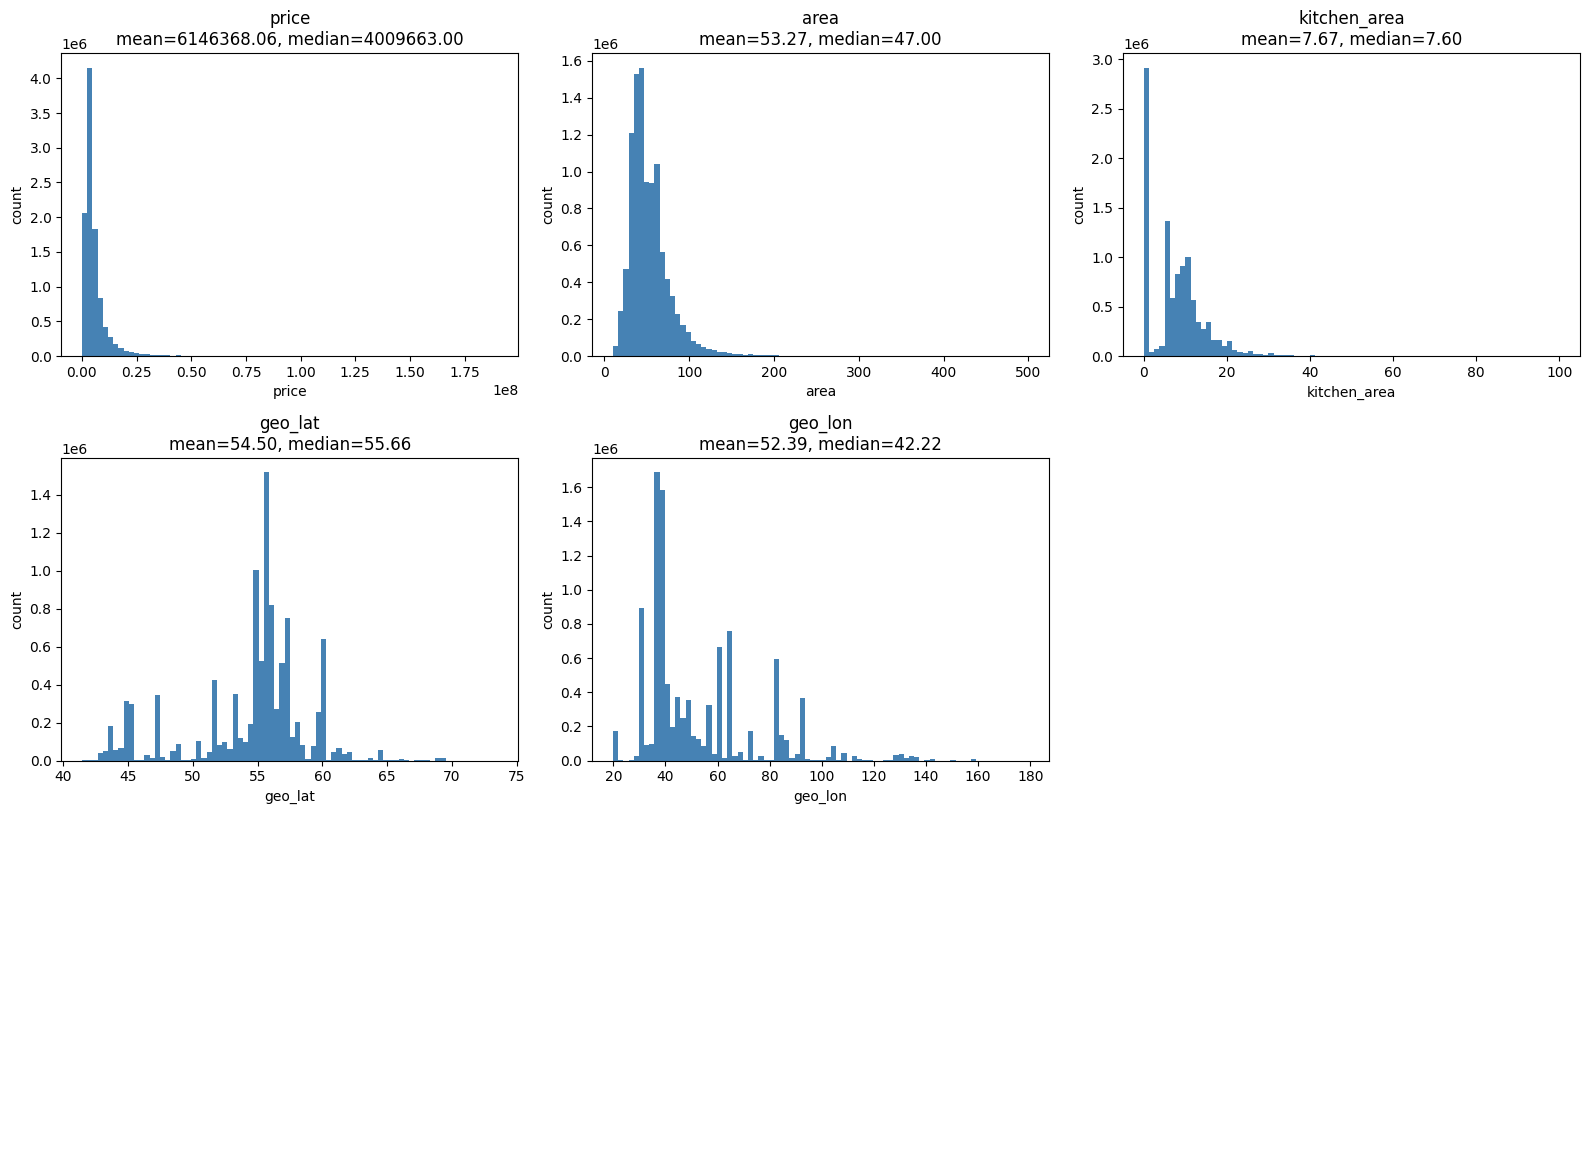

In [35]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.ravel()

for i, col in enumerate(numeric_cols):
    axes[i].hist(df_clean[col].dropna(), bins=80, color="steelblue", edgecolor="none")
    axes[i].set_title(f"{col}\nmean={df_clean[col].mean():.2f}, median={df_clean[col].median():.2f}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("count")

# Убираем пустые оси
for j in range(len(numeric_cols), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

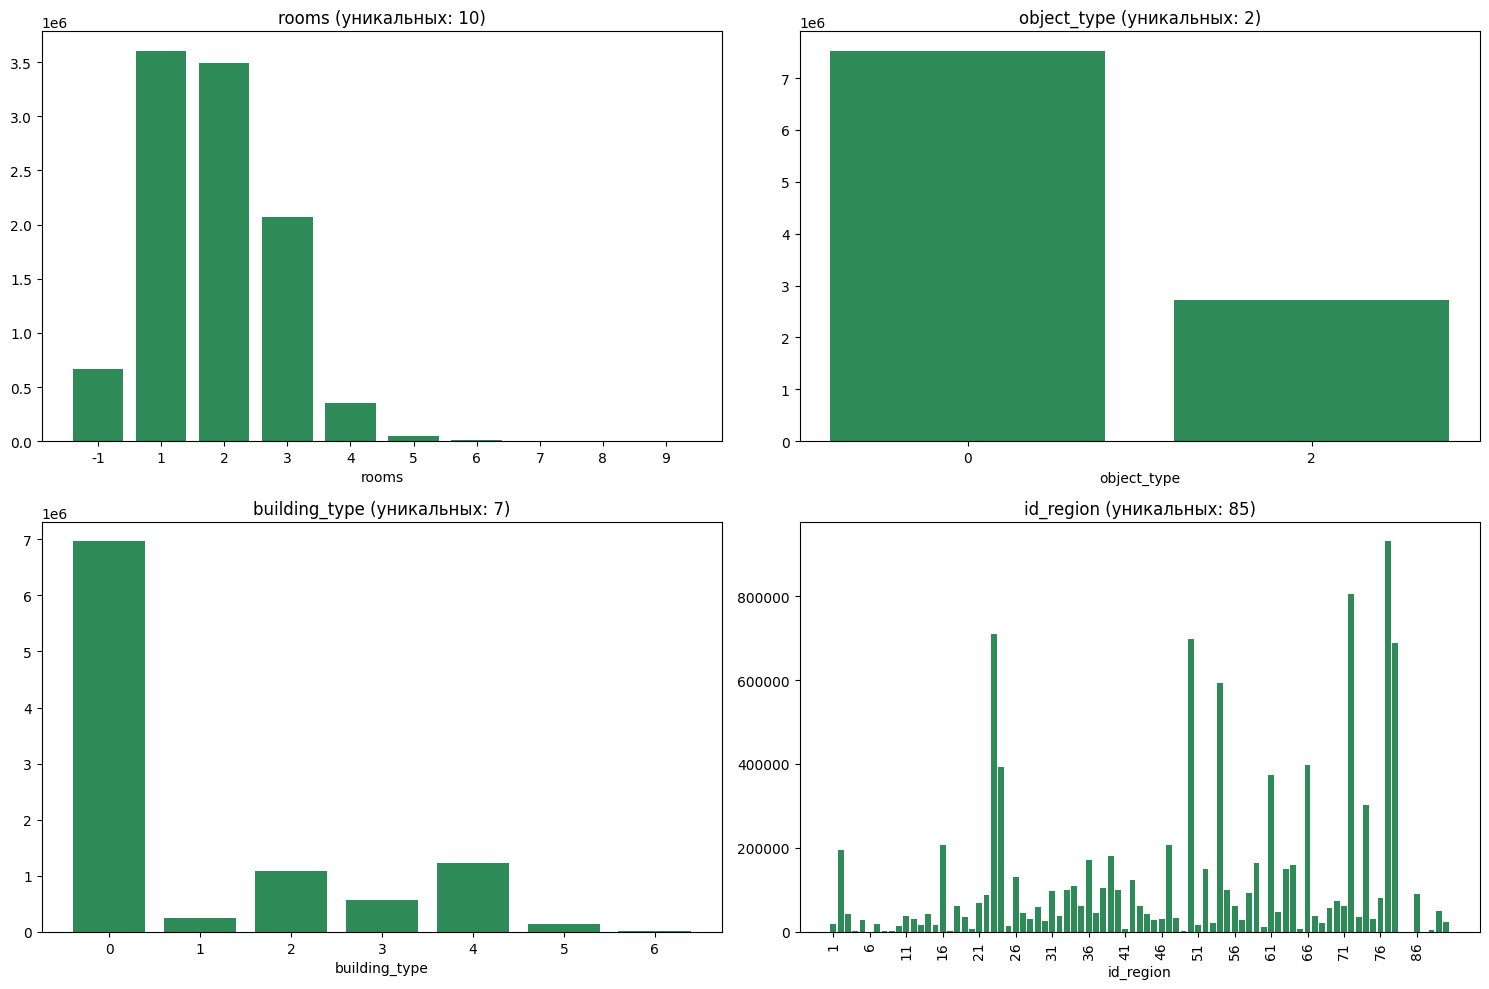

In [36]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, col in zip(axes.ravel(), cat_cols):
    vc = df_clean[col].value_counts().sort_index()
    ax.bar(vc.index.astype(str), vc.values, color="seagreen")
    ax.set_title(f"{col} (уникальных: {df_clean[col].nunique()})")
    ax.set_xlabel(col)
    ax.tick_params(axis="x", rotation=90 if col == "id_region" else 0)
    if col == "id_region":
        ax.set_xticks(ax.get_xticks()[::5])   # прореживаем подписи

plt.tight_layout()
plt.show()

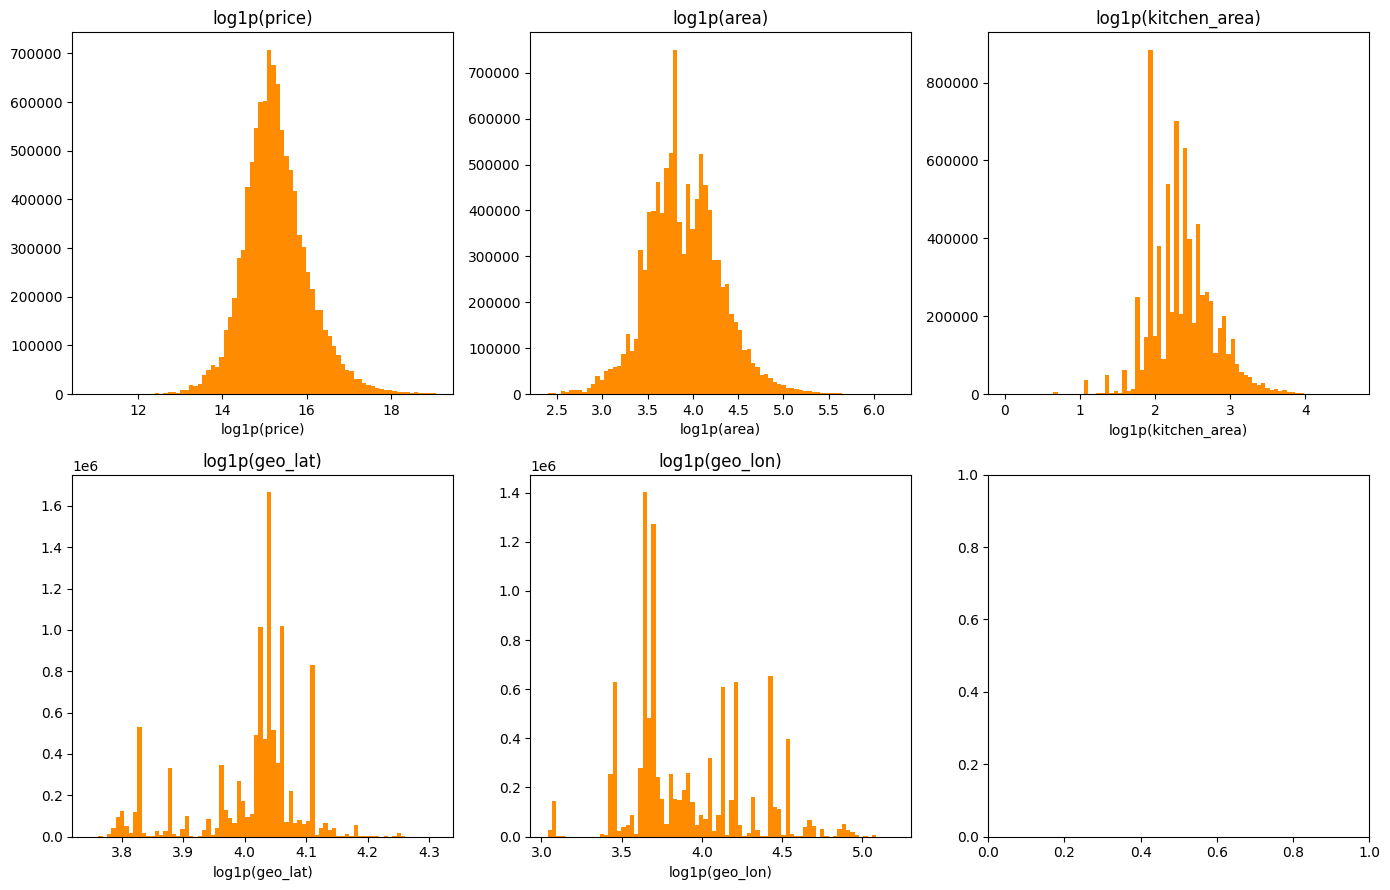

In [37]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for ax, col in zip(axes.ravel(), ["price", "area", "kitchen_area", "geo_lat", "geo_lon"]):
    data = df_clean[col].dropna()
    data = data[data > 0]
    ax.hist(np.log1p(data), bins=80, color="darkorange", edgecolor="none")
    ax.set_title(f"log1p({col})")
    ax.set_xlabel(f"log1p({col})")

plt.tight_layout()
plt.show()

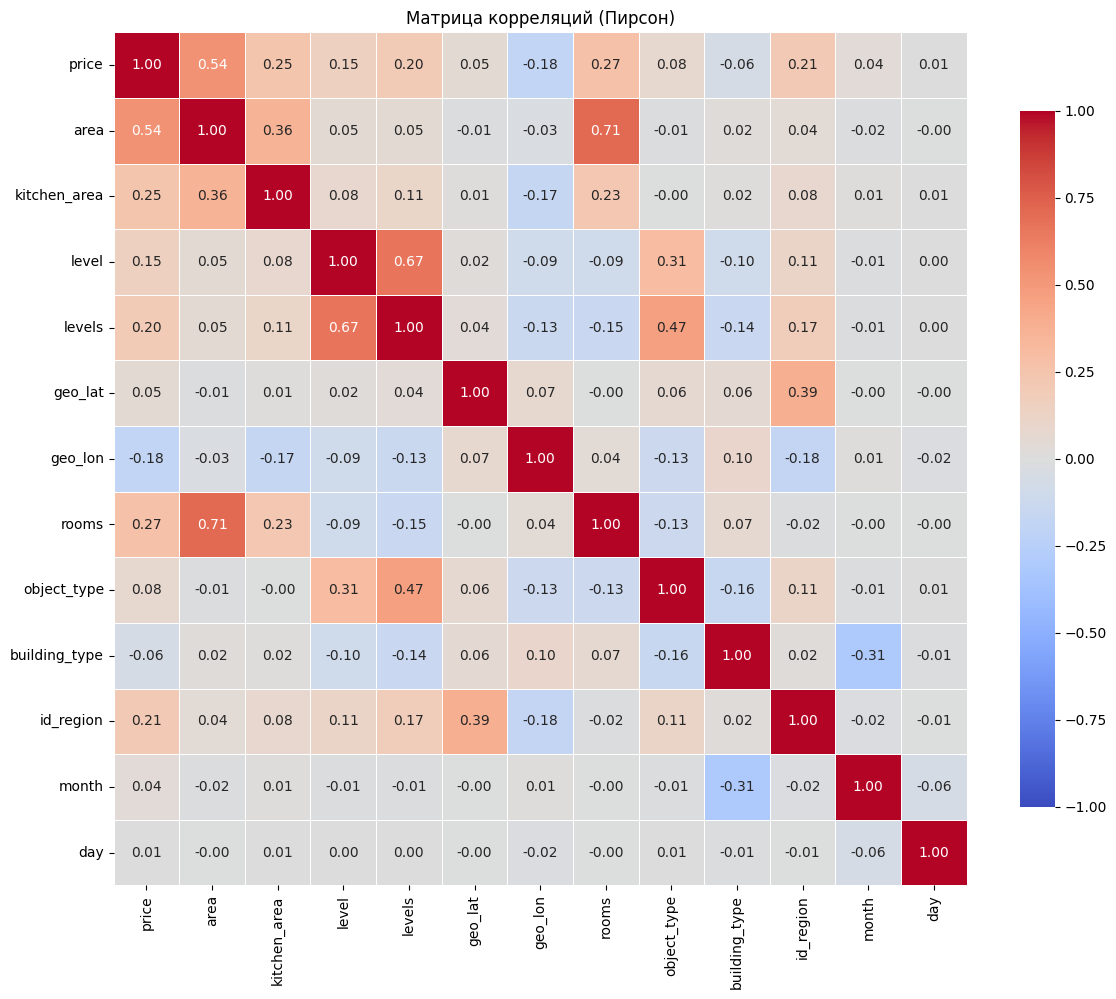

In [38]:
import seaborn as sns
# Только числовые признаки + price
corr_cols = ["price", "area", "kitchen_area", "level", "levels",
             "geo_lat", "geo_lon", "rooms", "object_type", "building_type", "id_region", "month", "day"]

corr = df_clean[corr_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Матрица корреляций (Пирсон)")
plt.tight_layout()
plt.show()

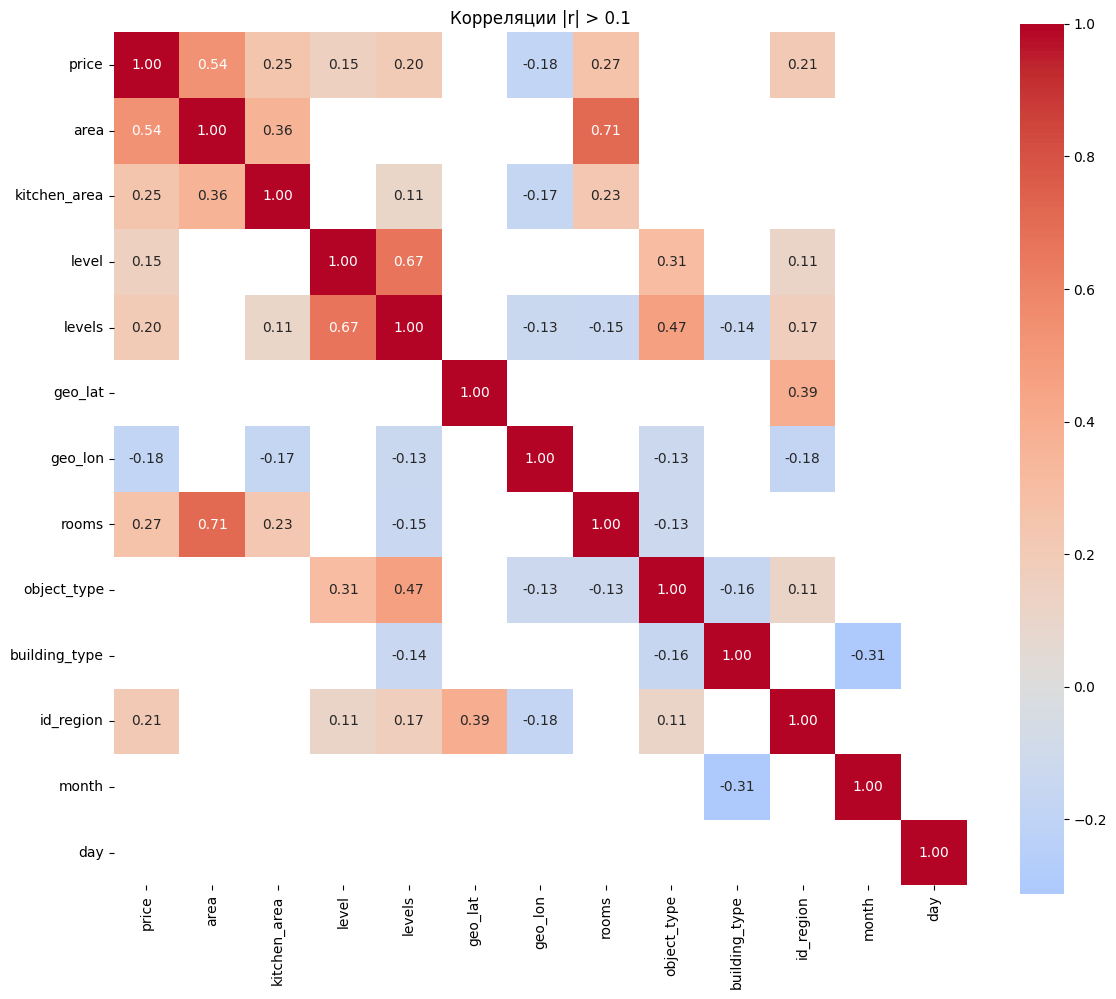

In [39]:
# Наиболее интересные корреляции
corr_filtered = corr.copy()
corr_filtered[np.abs(corr_filtered) < 0.1] = np.nan

plt.figure(figsize=(12, 10))
sns.heatmap(corr_filtered, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Корреляции |r| > 0.1")
plt.tight_layout()
plt.show()

После финальной валидации и филтрации кореляция должна быть лучше

## Работа с kitchen area и object type

In [40]:
# Все 0 → NaN
df_clean_new = df_clean.copy()
df_clean_new.loc[df_clean_new["kitchen_area"] == 0, "kitchen_area"] = np.nan

print(f"Пропусков: {df_clean_new['kitchen_area'].isna().sum():,}")
print(f"Доля: {df_clean_new['kitchen_area'].isna().mean()*100:.2f}%")

Пропусков: 2,907,407
Доля: 28.38%


In [41]:
features_reg = ["area", "rooms", "id_region", "level", "levels",
                "geo_lat", "geo_lon", "object_type"]

known = df_clean_new[df_clean_new["kitchen_area"].notna()]
unknown = df_clean_new[df_clean_new["kitchen_area"].isna()]

print(f"Известных: {len(known):,}")
print(f"Пропущенных: {len(unknown):,}")

Известных: 7,337,936
Пропущенных: 2,907,407


In [42]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

In [43]:
sample = known.sample(n=500_000, random_state=42)

X_tr, X_val, y_tr, y_val = train_test_split(
    sample[features_reg], sample["kitchen_area"],
    test_size=0.2, random_state=42
)

check = HistGradientBoostingRegressor(
    max_iter=500, learning_rate=0.03, max_depth=12,
    min_samples_leaf=20, l2_regularization=0.1
)
check.fit(X_tr, y_tr)
pred_val = check.predict(X_val)

mae = mean_absolute_error(y_val, pred_val)
r2 = r2_score(y_val, pred_val)
print(f"MAE: {mae:.3f} м²")
print(f"R²:  {r2:.3f}")

MAE: 2.228 м²
R²:  0.574


In [44]:
from sklearn.metrics import mean_absolute_error
import numpy as np

# Медиана по rooms как «плохой» baseline
median_by_rooms = known.groupby("rooms")["kitchen_area"].median()
fallback_pred = X_val["rooms"].map(median_by_rooms).fillna(known["kitchen_area"].median())

mae_fallback = mean_absolute_error(y_val, fallback_pred)
print(f"MAE модели:    {mae:.3f}")
print(f"MAE медианы:   {mae_fallback:.3f}")
print(f"Улучшение:     {(mae_fallback - mae) / mae_fallback * 100:.1f}%")

MAE модели:    2.228
MAE медианы:   3.650
Улучшение:     39.0%


In [46]:
print("Строк с kitchen_area < 3:", (df_clean_new["kitchen_area"] < 3).sum())
print(df_clean_new[df_clean_new["kitchen_area"] < 3]["kitchen_area"].describe())
print(df_clean_new[df_clean_new["kitchen_area"] < 3]["rooms"].value_counts())

Строк с kitchen_area < 3: 48863
count   48863.00
mean        1.98
std         0.41
min         0.01
25%         2.00
50%         2.00
75%         2.00
max         2.99
Name: kitchen_area, dtype: float64
rooms
-1    34051
 1    11657
 2     2393
 3      627
 4      103
 5       19
 6        5
 7        4
 9        4
Name: count, dtype: int64


сойдёт

In [45]:
final_reg = HistGradientBoostingRegressor(
    max_iter=500, learning_rate=0.03, max_depth=12,
    min_samples_leaf=20, l2_regularization=0.1
)
final_reg.fit(known[features_reg], known["kitchen_area"])

predicted = np.clip(final_reg.predict(unknown[features_reg]), 3, 40)

df_clean_new.loc[df_clean_new["kitchen_area"].isna(), "kitchen_area"] = predicted

print(df_clean_new["kitchen_area"].describe())
print("\nМедианы по rooms:")
print(df_clean_new.groupby("rooms")["kitchen_area"].median())

count   10245343.00
mean          10.72
std            5.47
min            0.01
25%            7.00
50%            9.64
75%           13.00
max          100.00
Name: kitchen_area, dtype: float64

Медианы по rooms:
rooms
-1    5.00
 1    9.70
 2    9.89
 3   10.66
 4   11.50
 5   17.30
 6   20.00
 7   20.00
 8   19.35
 9   13.50
Name: kitchen_area, dtype: float64


как то неправдопободно, попробуем квантиль

In [49]:
from sklearn.ensemble import HistGradientBoostingRegressor

final_reg = HistGradientBoostingRegressor(
    loss="quantile",         # ← ключевое
    quantile=0.5,            # ← медиана
    max_iter=500, learning_rate=0.03, max_depth=12,
    min_samples_leaf=20, l2_regularization=0.1,
    random_state=42
)
final_reg.fit(known[features_reg], known["kitchen_area"])

predicted = np.clip(final_reg.predict(unknown[features_reg]), 3, 40)

# Сравниваем медианы
print(f"Медиана известных:     {known['kitchen_area'].median():.2f}")
print(f"Медиана предсказанных: {np.median(predicted):.2f}")

Медиана известных:     9.20
Медиана предсказанных: 9.70


In [50]:
print("Медиана всех known:", known["kitchen_area"].median())
print("Медиана без студий:", known[known["rooms"] != -1]["kitchen_area"].median())
print("Медиана студий:    ", known[known["rooms"] == -1]["kitchen_area"].median())

Медиана всех known: 9.2
Медиана без студий: 9.5
Медиана студий:     5.0


In [52]:
# Предсказания новой модели
pred_series = pd.Series(predicted, index=unknown.index)
print("Медианы предсказанных по rooms:")
print(unknown.assign(kitchen_pred=pred_series).groupby("rooms")["kitchen_pred"].median())

Медианы предсказанных по rooms:
rooms
-1    5.10
 1    9.91
 2   10.49
 3   12.00
 4   12.61
 5   19.45
 6   20.08
 7   20.04
 8   21.20
 9   19.91
Name: kitchen_pred, dtype: float64


Херня получилась, попробую искусственно сдвинуть вниз

# Baseline